# What Discourages Students from Using AI for Homework?
**Shiyao Liang (slian088) | CS105 Fall 2026**


## Data cleaning summary

- Keep the six homework-deterrent questions and class standing. Trim spaces and keep blanks as missing.
- Code Not at all = 0, A little = 1, Somewhat = 2, and A lot = 3. Flag unexpected answers.
- For the radar chart, keep Freshman–Senior and use valid answers per item. Exclude the one concurrent response from this chart.
- For paired tests, require all four score items. Average independent learning and future independence for the learning score; average distrust and difficulty using AI for the trust/skill score.
- For the chi-squared test, require both class-rule and cheating answers. Group scores 0–1 as Lower and 2–3 as Higher.


## Research questions

- Which factors discourage AI use, and how do ratings differ by year?
- Are learning-related ratings higher than trust/skill ratings?
- Are class-rule and cheating-related deterrents associated?


## Data source

93 responses and 175 columns from `data/uncleaned_data.xlsx`, sheet `Form Responses 1`. We use six deterrent questions (DE–DJ) and class standing.


In [1]:
from pathlib import Path
import hashlib
import pandas as pd

# Locate the repository whether launched from this folder or the repository root.
repo_root = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / 'data' / "uncleaned_data.xlsx").is_file()),
    None,
)
if repo_root is None:
    raise FileNotFoundError('Could not locate data/uncleaned_data.xlsx in the repository.')
source_path = repo_root / 'data' / "uncleaned_data.xlsx"
output_dir = repo_root / 'working_folders' / 'slian088'
data = pd.read_excel(source_path, sheet_name='Form Responses 1')
print(f'Source: {source_path.relative_to(repo_root)}')
print(f'Responses: {len(data)}; columns: {data.shape[1]}')
print('Workbook SHA-256:', hashlib.sha256(source_path.read_bytes()).hexdigest())


Source: data/uncleaned_data.xlsx
Responses: 93; columns: 175
Workbook SHA-256: 278beaf658088440762c000a3b362a01e9a7d88120c711e122c3e135240831c0


## Variables

The code selects six questions by wording and gives them short names. `source_excel_row` identifies the original spreadsheet row.


In [2]:
factors = {
    'learn_myself': ('DE', 'I want to learn the material myself'),
    'future_independence': ('DF', 'I need to be able to do it without AI later'),
    'distrust_answers': ('DG', 'I don’t trust its answers'),
    'class_rules': ('DH', "My class rules don't allow it"),
    'feels_like_cheating': ('DI', 'I feel like I am cheating'),
    'lack_of_ai_skills': ('DJ', "I don't know how to use it well"),
}
selected = {}
for short_name, (excel_col, wording) in factors.items():
    matches = [c for c in data.columns
               if c.startswith('When you are working on a homework assignment,')
               and c.strip().endswith(f'[{wording}]')]
    if len(matches) != 1:
        raise ValueError(f'Expected exactly one column for {short_name}: {matches}')
    selected[matches[0]] = short_name

raw_factors = data[list(selected)].rename(columns=selected).copy()
raw_factors.index = pd.RangeIndex(2, len(data) + 2, name='source_excel_row')
variable_dictionary = pd.DataFrame([
    {'variable': name, 'original_excel_column': col, 'factor': wording}
    for name, (col, wording) in factors.items()
])
print(variable_dictionary.to_string(index=False))
print('\nFirst five responses (original text):')
print(raw_factors.head().to_string())


           variable original_excel_column                                      factor
       learn_myself                    DE         I want to learn the material myself
future_independence                    DF I need to be able to do it without AI later
   distrust_answers                    DG                   I don’t trust its answers
        class_rules                    DH               My class rules don't allow it
feels_like_cheating                    DI                   I feel like I am cheating
  lack_of_ai_skills                    DJ             I don't know how to use it well

First five responses (original text):
                 learn_myself future_independence distrust_answers class_rules feels_like_cheating lack_of_ai_skills
source_excel_row                                                                                                    
2                         NaN                 NaN              NaN         NaN                 NaN               NaN
3       

## Data cleaning

| Answer | Score |
|---|---:|
| Not at all | 0 |
| A little | 1 |
| Somewhat | 2 |
| A lot | 3 |

Trim spaces, keep blanks as missing, and flag unexpected answers. Calculate each factor's mean from its valid answers.


In [3]:
score_map = {'Not at all': 0, 'A little': 1, 'Somewhat': 2, 'A lot': 3}
text_factors = raw_factors.apply(lambda col: col.astype('string').str.strip())
text_factors = text_factors.replace('', pd.NA)
unexpected = {
    col: sorted(set(text_factors[col].dropna()) - set(score_map))
    for col in text_factors
}
unexpected = {col: values for col, values in unexpected.items() if values}
if unexpected:
    raise ValueError(f'Unrecognized survey answers: {unexpected}')
clean_factors = text_factors.apply(lambda col: col.map(score_map)).astype('Int64')

missingness = pd.DataFrame({
    'valid_n': clean_factors.count(),
    'missing_n': clean_factors.isna().sum(),
})
print(missingness.to_string())
print(f'\nResponses with all six factors answered: {len(clean_factors.dropna())}')
print(f'Responses with no factors answered: {clean_factors.isna().all(axis=1).sum()}')
print('\nFirst five encoded responses (NA means missing):')
print(clean_factors.head().to_string())


                     valid_n  missing_n
learn_myself              85          8
future_independence       86          7
distrust_answers          85          8
class_rules               84          9
feels_like_cheating       86          7
lack_of_ai_skills         84          9

Responses with all six factors answered: 81
Responses with no factors answered: 7

First five encoded responses (NA means missing):
                  learn_myself  future_independence  distrust_answers  class_rules  feels_like_cheating  lack_of_ai_skills
source_excel_row                                                                                                          
2                         <NA>                 <NA>              <NA>         <NA>                 <NA>               <NA>
3                            2                    3                 0            3                    1                  1
4                         <NA>                 <NA>              <NA>         <NA>             

## Descriptive statistics

Report valid and missing counts, means, medians, and the percentage answering Somewhat or A lot. Percentages use valid answers only. Means treat the four ordered categories as equally spaced.


In [4]:
valid_n = clean_factors.count()
high_count = clean_factors.ge(2).sum()
summary = pd.DataFrame({
    'factor': [factors[name][1] for name in clean_factors.columns],
    'valid_n': valid_n,
    'missing_n': clean_factors.isna().sum(),
    'mean_score': clean_factors.mean(),
    'median_score': clean_factors.median(),
    'somewhat_or_a_lot_n': high_count,
    'somewhat_or_a_lot_pct': high_count.div(valid_n.replace(0, float('nan'))).mul(100),
})
summary.index.name = 'variable'
summary = summary.sort_values('mean_score', ascending=False)
print(summary.to_string(index=False, float_format=lambda x: f'{x:.2f}'))

counts = pd.DataFrame({
    col: text_factors[col].value_counts().reindex(list(score_map), fill_value=0)
    for col in text_factors
}).T
counts.index.name = 'variable'
percentages = counts.div(valid_n.replace(0, float('nan')), axis=0).mul(100)
print('\nFull response counts:')
print(counts.to_string())
print('\nPercentages among valid answers:')
print(percentages.round(2).to_string())


                                     factor  valid_n  missing_n  mean_score  median_score  somewhat_or_a_lot_n  somewhat_or_a_lot_pct
I need to be able to do it without AI later       86          7        2.30          3.00                   69                  80.23
        I want to learn the material myself       85          8        2.06          2.00                   61                  71.76
              My class rules don't allow it       84          9        1.81          2.00                   55                  65.48
                  I feel like I am cheating       86          7        1.55          2.00                   45                  52.33
                  I don’t trust its answers       85          8        1.39          2.00                   44                  51.76
            I don't know how to use it well       84          9        0.57          0.00                   13                  15.48

Full response counts:
                     Not at all  A litt

## Save summary files

Save the selected answers, scores, summaries, response counts, and variable dictionary to `working_folders/slian088`. Missing values are blank.


In [5]:
exports = {
    'deterrents_raw.csv': raw_factors,
    'deterrents_cleaned.csv': clean_factors,
    'deterrents_summary.csv': summary,
    'deterrents_response_counts.csv': counts,
    'deterrents_response_percentages.csv': percentages,
}
for filename, frame in exports.items():
    frame.to_csv(output_dir / filename, encoding='utf-8', na_rep='')
variable_dictionary.to_csv(output_dir / 'deterrents_variable_dictionary.csv', index=False)
print('Saved:', ', '.join([*exports, 'deterrents_variable_dictionary.csv']))


Saved: deterrents_raw.csv, deterrents_cleaned.csv, deterrents_summary.csv, deterrents_response_counts.csv, deterrents_response_percentages.csv, deterrents_variable_dictionary.csv


#### Visualization: Do AI deterrents differ by year?

**What we want to learn:** How do the six deterrents differ across years?

Each color and marker represents a year. Lines show mean scores on the same 0–3 scale. The legend gives group sizes, and the output gives valid counts per item. The chart excludes one concurrent student whose year is unclear.


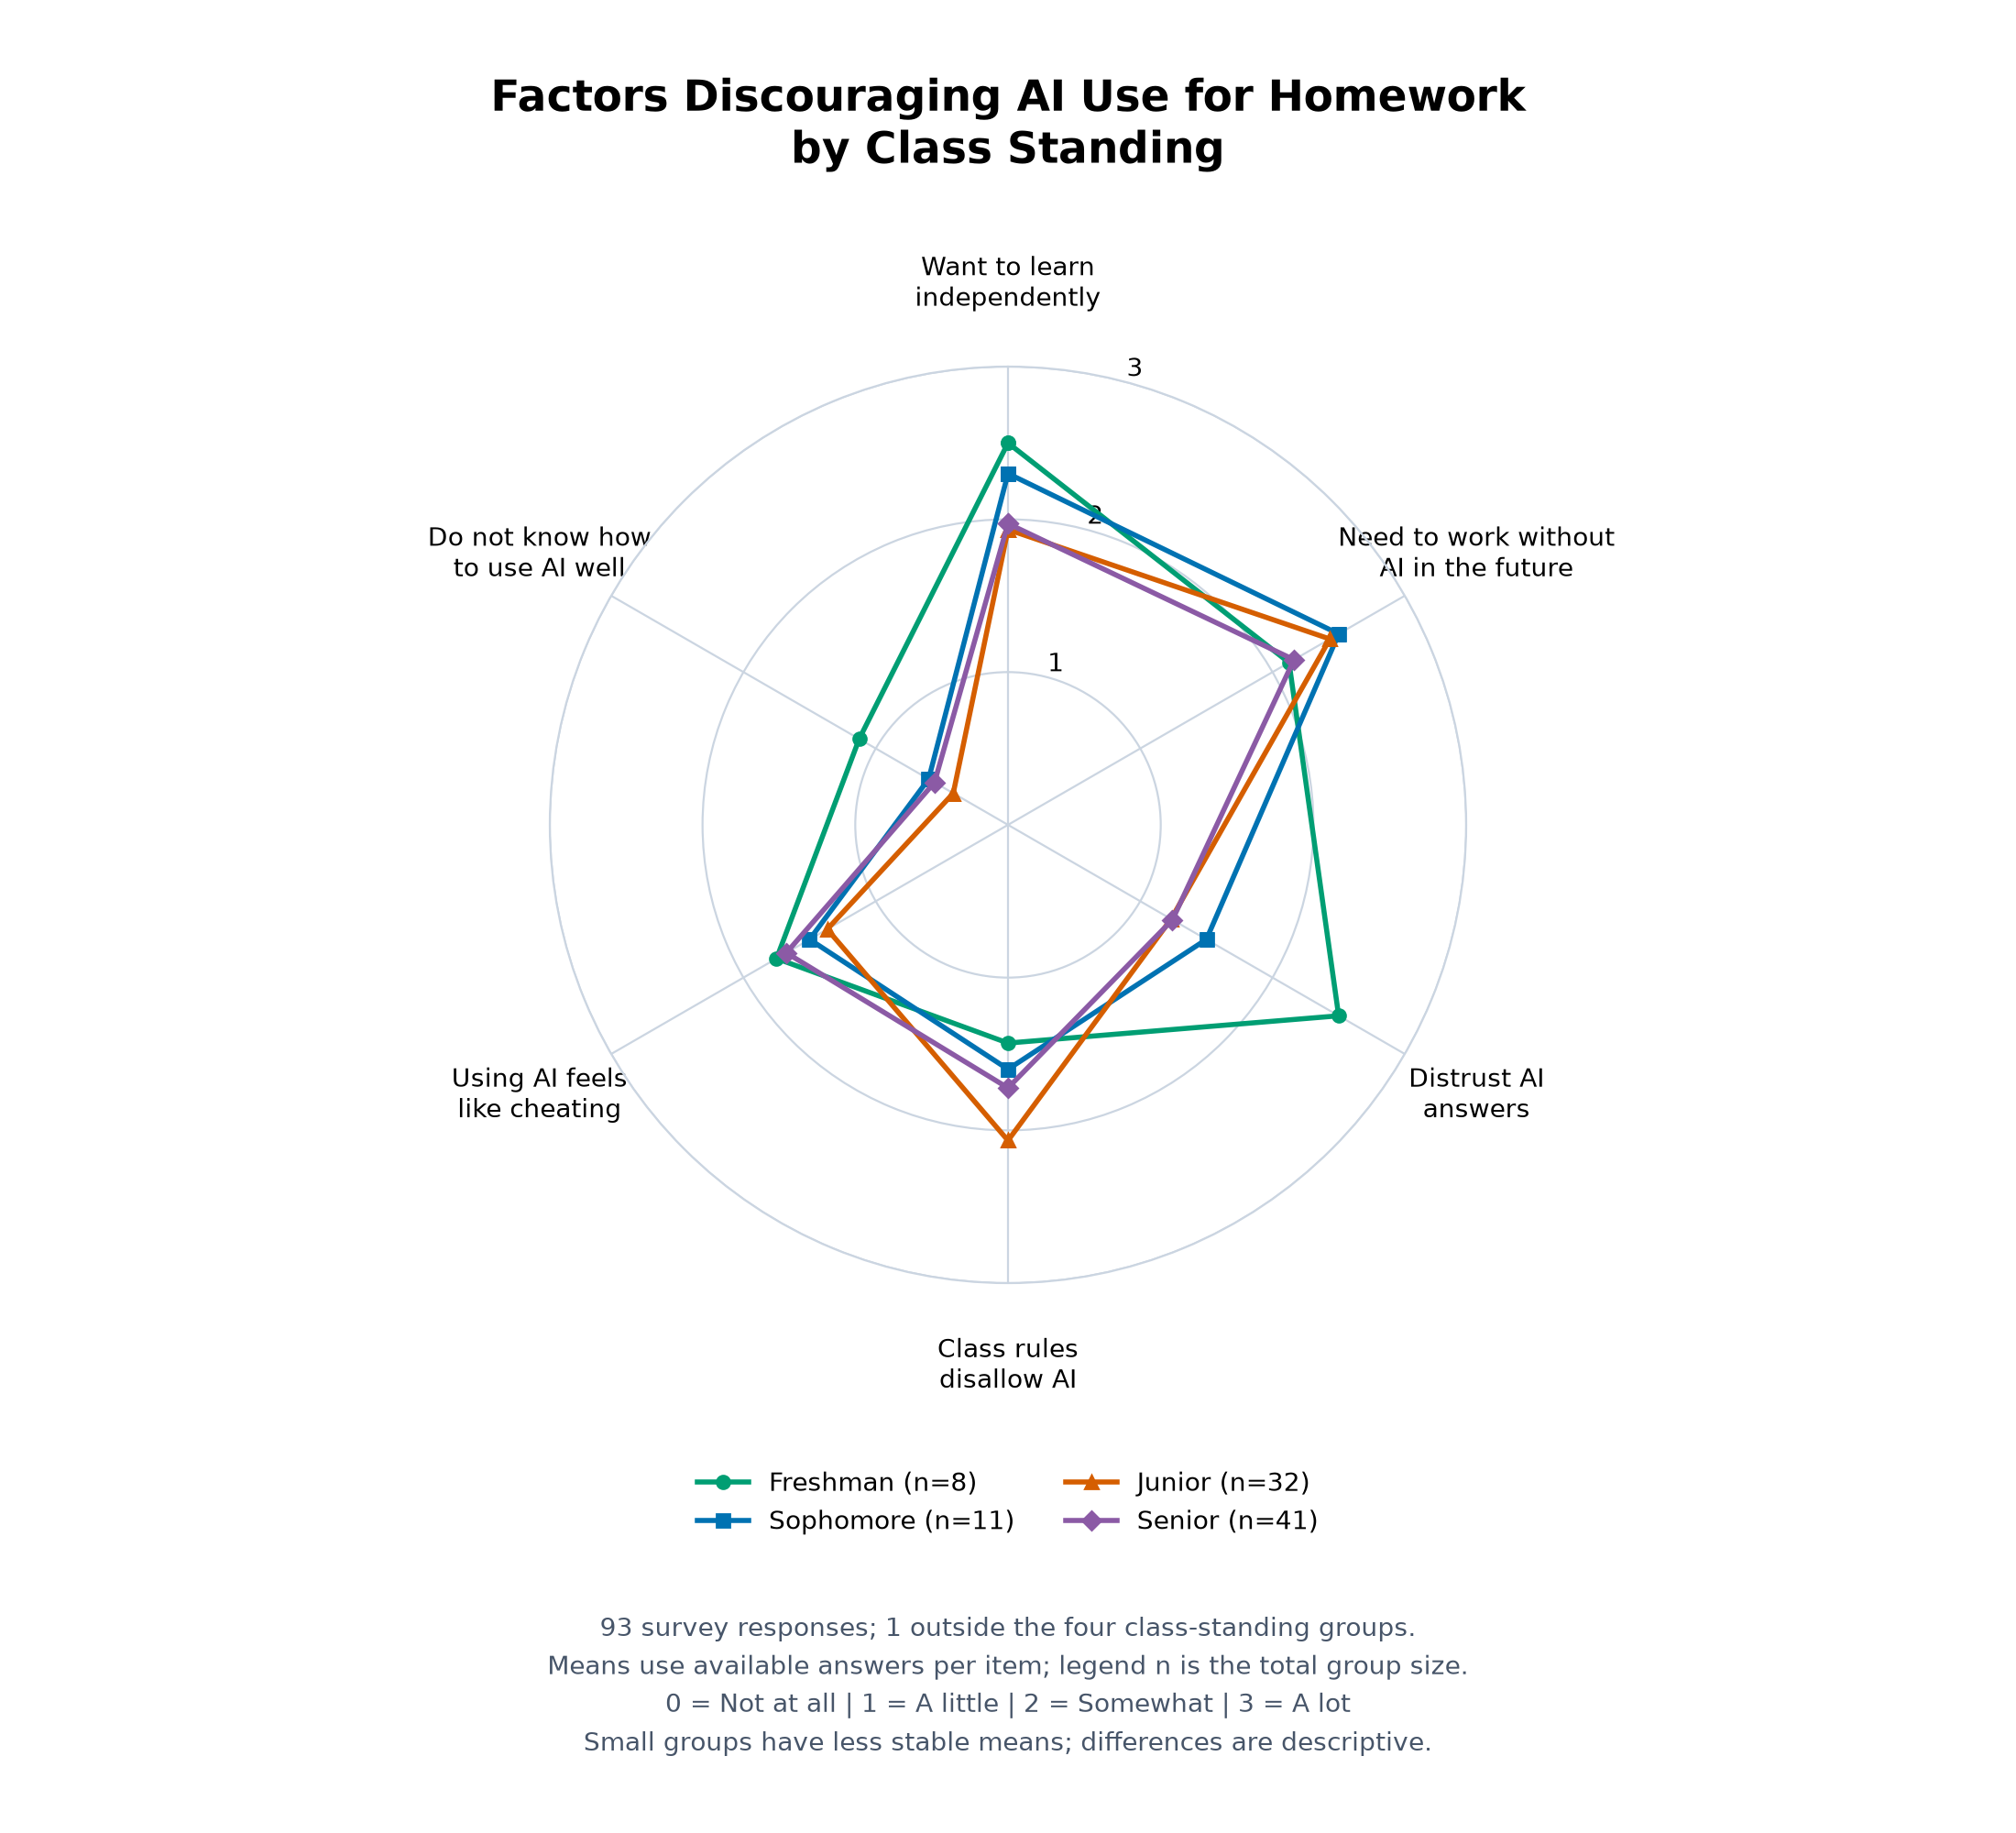

Group mean ratings:
                learn_myself  future_independence  distrust_answers  class_rules  feels_like_cheating  lack_of_ai_skills
class_standing                                                                                                          
Freshman                 2.5                 2.12               2.5         1.43                 1.75               1.12
Sophomore                2.3                  2.5               1.5          1.6                  1.5                0.6
Junior                  1.93                 2.43              1.23         2.07                 1.37               0.41
Senior                  1.97                 2.16              1.24         1.72                 1.68               0.56

Valid responses per group and factor:
                learn_myself  future_independence  distrust_answers  class_rules  feels_like_cheating  lack_of_ai_skills
class_standing                                                                                

In [6]:
import numpy as np
import matplotlib.pyplot as plt

order = list(factors)
year_order = ['Freshman', 'Sophomore', 'Junior', 'Senior']
# Use row positions because clean_factors is indexed by original Excel row.
class_standing = pd.Series(
    data['What is your current class standing?'].astype('string').str.strip().to_numpy(),
    index=clean_factors.index, name='class_standing',
)
year_data = clean_factors[order].join(class_standing)
year_data = year_data[year_data['class_standing'].isin(year_order)]
year_means = year_data.groupby('class_standing')[order].mean().reindex(year_order)
year_counts = year_data.groupby('class_standing')[order].count().reindex(year_order)
year_sizes = year_data.groupby('class_standing').size().reindex(year_order, fill_value=0)
label_text = [
    'Want to learn\nindependently', 'Need to work without\nAI in the future',
    'Distrust AI\nanswers', 'Class rules\ndisallow AI',
    'Using AI feels\nlike cheating', 'Do not know how\nto use AI well',
]
angles = np.linspace(0, 2 * np.pi, len(order), endpoint=False)
closed_angles = np.r_[angles, angles[0]]
fig, ax = plt.subplots(figsize=(11, 10), subplot_kw={'projection': 'polar'})
fig.subplots_adjust(left=0.20, right=0.80, top=0.80, bottom=0.30)
ax.set_theta_offset(np.pi / 2)
ax.set_theta_direction(-1)
ax.set_ylim(0, 3)
ax.set_yticks([1, 2, 3])
ax.set_rlabel_position(15)
ax.set_xticks(angles)
ax.set_xticklabels(label_text, fontsize=10)
ax.tick_params(axis='x', pad=22)
ax.grid(color='#cbd5e1', linewidth=0.8)
ax.spines['polar'].set_color('#cbd5e1')
colors = ['#009E73', '#0072B2', '#D55E00', '#8B5AA5']
markers = ['o', 's', '^', 'D']
for year, color, marker in zip(year_order, colors, markers):
    values = year_means.loc[year].astype(float).to_numpy()
    ax.plot(closed_angles, np.r_[values, values[0]], color=color,
            marker=marker, linewidth=2, markersize=5,
            label=f'{year} (n={year_sizes[year]})')
fig.suptitle('Factors Discouraging AI Use for Homework\nby Class Standing',
             fontsize=17, fontweight='bold', y=0.96)
fig.legend(*ax.get_legend_handles_labels(), loc='lower center',
           bbox_to_anchor=(0.5, 0.15), ncol=2, frameon=False)
excluded_year_n = len(data) - len(year_data)
fig.text(0.5, 0.045,
         f'{len(data)} survey responses; {excluded_year_n} outside the four class-standing groups.\n'
         'Means use available answers per item; legend n is the total group size.\n'
         '0 = Not at all | 1 = A little | 2 = Somewhat | 3 = A lot\n'
         'Small groups have less stable means; differences are descriptive.',
         ha='center', fontsize=10, color='#475569', linespacing=1.5)
radar_path = output_dir / 'deterrents_radar.png'
fig.savefig(radar_path, dpi=200, facecolor='white')
plt.show()
plt.close(fig)
print('Group mean ratings:')
print(year_means.round(2).to_string())
print('\nValid responses per group and factor:')
print(year_counts.to_string())
print('\nSaved:', radar_path.name)


**Interpretation:** Future independence had the highest mean for sophomores (2.50), juniors (2.43), and seniors (2.16). For freshmen, independent learning and distrust of AI tied at 2.50. Difficulty using AI had the lowest mean in every group.

Freshman (n=8) and sophomore (n=11) groups are small. The chart describes differences; year-group significance has not been tested.


#### Hypothesis: Learning-related ratings are higher than trust/skill ratings

**Scores:**

- Learning score = average of independent learning and future independence.
- Trust/skill score = average of distrust and difficulty using AI.
- Difference = learning score − trust/skill score.

**Test and justification:** Use complete answers to all four items. Scores are paired within each respondent. Run a two-sided Wilcoxon signed-rank test at α = 0.05, using an asymptotic calculation with tie and continuity corrections and excluding zero differences from ranking. A location-shift interpretation requires approximately symmetric differences.

An exact two-sided sign test checks whether positive and negative differences are equally likely, without requiring symmetry. Both tests assume independent respondents. These custom scores and tests are exploratory.


In [7]:
from scipy import stats
import json

required = ['learn_myself', 'future_independence', 'distrust_answers', 'lack_of_ai_skills']
paired = clean_factors[required].dropna().astype(float).copy()
paired['learning_score'] = paired[['learn_myself', 'future_independence']].mean(axis=1)
paired['trust_skill_score'] = paired[['distrust_answers', 'lack_of_ai_skills']].mean(axis=1)
paired['difference'] = paired['learning_score'] - paired['trust_skill_score']
difference = paired['difference'].to_numpy()
n_positive = int((difference > 0).sum())
n_negative = int((difference < 0).sum())
n_zero = int((difference == 0).sum())
n_nonzero = n_positive + n_negative
if n_nonzero == 0:
    raise ValueError('All paired differences are zero; no signed-rank or sign test is informative.')
wilcoxon_result = stats.wilcoxon(
    difference, alternative='two-sided', zero_method='wilcox',
    method='asymptotic', correction=True,
)
sign_result = stats.binomtest(n_positive, n_nonzero, p=0.5, alternative='two-sided')
nonzero = difference[difference != 0]
ranks = stats.rankdata(np.abs(nonzero))
w_plus = float(ranks[nonzero > 0].sum())
w_minus = float(ranks[nonzero < 0].sum())
rank_biserial = (w_plus - w_minus) / (w_plus + w_minus)
test_results = {
    'alpha': 0.05, 'alternative': 'two-sided',
    'complete_pairs': len(paired), 'excluded_incomplete_responses': len(data) - len(paired),
    'positive_differences': n_positive, 'negative_differences': n_negative,
    'zero_differences': n_zero, 'nonzero_pairs': n_nonzero,
    'learning_score_mean': float(paired['learning_score'].mean()),
    'trust_skill_score_mean': float(paired['trust_skill_score'].mean()),
    'mean_paired_difference': float(np.mean(difference)),
    'median_paired_difference': float(np.median(difference)),
    'difference_q1': float(np.quantile(difference, 0.25)),
    'difference_q3': float(np.quantile(difference, 0.75)),
    'wilcoxon_statistic': float(wilcoxon_result.statistic),
    'wilcoxon_p_value': float(wilcoxon_result.pvalue),
    'wilcoxon_method': 'tie-corrected asymptotic; continuity correction; zero_method=wilcox',
    'matched_pairs_rank_biserial': rank_biserial,
    'exact_sign_test_p_value': float(sign_result.pvalue),
}
print(json.dumps(test_results, indent=2))
print('\nObserved paired-difference distribution:')
print(paired['difference'].value_counts().sort_index().to_string())
paired.to_csv(output_dir / 'deterrents_paired_scores.csv')
(output_dir / 'deterrents_test_results.json').write_text(json.dumps(test_results, indent=2) + '\n')


{
  "alpha": 0.05,
  "alternative": "two-sided",
  "complete_pairs": 83,
  "excluded_incomplete_responses": 10,
  "positive_differences": 60,
  "negative_differences": 2,
  "zero_differences": 21,
  "nonzero_pairs": 62,
  "learning_score_mean": 2.1566265060240966,
  "trust_skill_score_mean": 0.9939759036144579,
  "mean_paired_difference": 1.1626506024096386,
  "median_paired_difference": 1.5,
  "difference_q1": 0.0,
  "difference_q3": 2.0,
  "wilcoxon_statistic": 31.5,
  "wilcoxon_p_value": 2.680960554745181e-11,
  "wilcoxon_method": "tie-corrected asymptotic; continuity correction; zero_method=wilcox",
  "matched_pairs_rank_biserial": 0.967741935483871,
  "exact_sign_test_p_value": 8.474124180146703e-16
}

Observed paired-difference distribution:
difference
-1.5     1
-0.5     1
 0.0    21
 0.5     5
 1.0    12
 1.5    18
 2.0    14
 2.5     8
 3.0     3


In [8]:
conclusion = (
    f'Among {len(paired)} complete pairs, the learning score averaged '
    f'{paired["learning_score"].mean():.2f} and the trust/skill score averaged '
    f'{paired["trust_skill_score"].mean():.2f}. The mean paired difference was '
    f'{np.mean(difference):.2f}. Two-sided p-values: Wilcoxon '
    f'{wilcoxon_result.pvalue:.3g}; exact sign test {sign_result.pvalue:.3g}.'
)
(output_dir / 'deterrents_interpretation.txt').write_text(conclusion + '\n');


**Result and conclusion:** For 83 complete pairs, learning scores averaged 2.16 and trust/skill scores averaged 0.99. The mean paired difference was 1.16. Wilcoxon W = 31.5, p = 2.68e-11; sign-test p = 8.47e-16. The results support higher learning-related ratings. Ten incomplete responses were excluded.


#### Hypothesis: Class-rule and cheating-related deterrents are associated

**H0:** The two deterrents are independent.

**H1:** The two deterrents are associated.

**Grouping:** Lower = Not at all / A little. Higher = Somewhat / A lot. This split separates weaker and stronger barriers but loses detail.

**Test and justification:** Use a 2 × 2 chi-squared independence test with Yates correction at α = 0.05. Include respondents who answered both items. Each respondent enters one cell, and all expected counts must be at least 5. Responses are assumed independent.

The class-rule item measures a reported barrier, not the actual course policy.


In [9]:
from scipy import stats

chi_answers = clean_factors[['class_rules', 'feels_like_cheating']].dropna()
chi_group_map = {0: 'Lower deterrence', 1: 'Lower deterrence',
                 2: 'Higher deterrence', 3: 'Higher deterrence'}
chi_groups = chi_answers.apply(lambda column: column.map(chi_group_map))
chi_levels = ['Lower deterrence', 'Higher deterrence']
chi_observed = pd.crosstab(
    chi_groups['class_rules'], chi_groups['feels_like_cheating'],
).reindex(index=chi_levels, columns=chi_levels, fill_value=0)
chi_observed.index.name = 'Class-rule deterrence'
chi_observed.columns.name = 'Cheating-related deterrence'
if (chi_observed.sum(axis=0) == 0).any() or (chi_observed.sum(axis=1) == 0).any():
    raise ValueError('Both deterrence groups must be represented for each item.')
chi_statistic, chi_p_value, chi_dof, chi_expected_array = stats.chi2_contingency(
    chi_observed, correction=True,
)
chi_expected = pd.DataFrame(
    chi_expected_array, index=chi_observed.index, columns=chi_observed.columns,
)
if (chi_expected_array < 5).any():
    raise ValueError('Expected cell counts are below 5; reassess the chi-squared method.')
chi_higher_percent = 100 * chi_observed['Higher deterrence'] / chi_observed.sum(axis=1)
print(f'Complete responses: {len(chi_answers)}; excluded: {len(data) - len(chi_answers)}')
print('Observed counts (rows = class rules; columns = cheating):')
print(chi_observed.to_string())
print('\nExpected counts:')
print(chi_expected.round(2).to_string())
print(f'\nPearson chi-squared with Yates correction: chi2({chi_dof}) = '
      f'{chi_statistic:.4f}, p = {chi_p_value:.6g}')
print('\nHigher cheating-related deterrence within each class-rule group (%):')
print(chi_higher_percent.round(1).to_string())


Complete responses: 84; excluded: 9
Observed counts (rows = class rules; columns = cheating):
Cheating-related deterrence  Lower deterrence  Higher deterrence
Class-rule deterrence                                           
Lower deterrence                           22                  7
Higher deterrence                          19                 36

Expected counts:
Cheating-related deterrence  Lower deterrence  Higher deterrence
Class-rule deterrence                                           
Lower deterrence                        14.15              14.85
Higher deterrence                       26.85              28.15

Pearson chi-squared with Yates correction: chi2(1) = 11.3720, p = 0.000745598

Higher cheating-related deterrence within each class-rule group (%):
Class-rule deterrence
Lower deterrence     24.1
Higher deterrence    65.5


**Result and conclusion:** Among 84 complete responses, higher cheating-related deterrence was reported by 65.5% of the higher class-rule group and 24.1% of the lower group. χ²(1) = 11.37, p = 0.000746, with Yates correction. All expected counts exceeded 5. Reject H0 at α = 0.05.

The two reported barriers are associated in this sample. This exploratory analysis does not establish causation.


## Limitations

This convenience sample uses self-reported answers. Unique respondents were not verified. Missing answers may affect the results, and findings may not generalize to other students.

## Group Contributions

| Member | Contribution |
|---|---|
| slian088 | Cleaned six items, summarized ratings, made the grouped radar chart, and ran paired and chi-squared tests. |

## Reproducibility

Run all cells in order with pandas, openpyxl, NumPy, Matplotlib, and SciPy. The chart uses valid answers per item. Paired tests require four complete items; the chi-squared test requires two.
